# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Rushil Nanga, Ashley Tibebe, Claire Curzan, Shravya Etta]

**Date:** [11/13/2026]

In [5]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

print("Original shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

df = df.dropna().drop_duplicates()

print("Cleaned shape:", df.shape)
print(df.dtypes)
print(df["DEATH_EVENT"].value_counts())

Original shape: (299, 13)
Missing values: 0
Duplicates: 0
Cleaned shape: (299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


Decision Tree:
MSE: 0.12920292989414742
R2: 0.40291328932101333

Linear Regression:
MSE: 0.13296455020890616
R2: 0.38552967811031813

Linear coefficients:
age                         6.001508e-03
anaemia                     9.949889e-03
creatinine_phosphokinase    3.887843e-05
diabetes                    8.877571e-03
ejection_fraction          -9.661164e-03
high_blood_pressure        -2.630328e-02
platelets                   6.922411e-08
serum_creatinine            5.826291e-02
serum_sodium               -9.746419e-03
sex                        -7.341870e-02
smoking                     1.532925e-02
time                       -2.872904e-03
dtype: float64


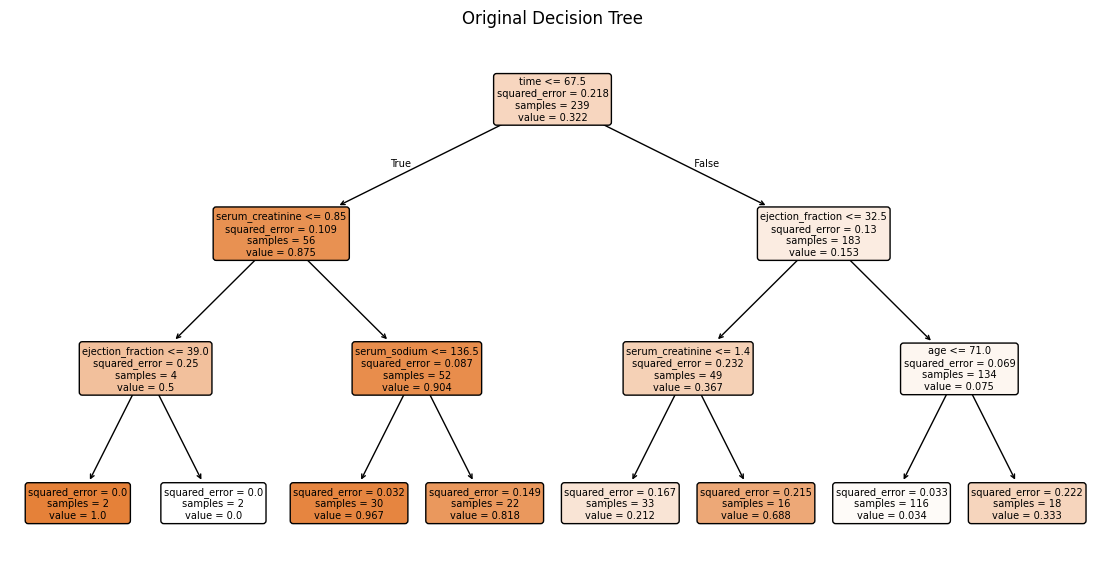

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = df.drop(columns=["DEATH_EVENT"])
y = df["DEATH_EVENT"]

seed = 10

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y
)

tree = DecisionTreeRegressor(max_depth=3, random_state=seed)
linear = LinearRegression()

tree.fit(X_train, y_train)
linear.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

print("Decision Tree:")
print("MSE:", mean_squared_error(y_test, tree_pred))
print("R2:", r2_score(y_test, tree_pred))

print("\nLinear Regression:")
print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2:", r2_score(y_test, linear_pred))

print("\nLinear coefficients:")
print(pd.Series(linear.coef_, index=X.columns))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.title("Original Decision Tree")
plt.show()

Seed: 30
Tree R2: 0.4404
Linear R2: 0.3188
Tree root feature: time

Seed: 50
Tree R2: 0.3204
Linear R2: 0.3082
Tree root feature: time

Seed: 70
Tree R2: 0.1968
Linear R2: 0.3013
Tree root feature: time

Seed: 90
Tree R2: 0.3732
Linear R2: 0.3133
Tree root feature: time

Linear coefficients across seeds:
                              30      50      70      90
age                       0.0048  0.0051  0.0042  0.0049
anaemia                  -0.0108  0.0023  0.0089 -0.0049
creatinine_phosphokinase  0.0000  0.0000  0.0001  0.0000
diabetes                  0.0695  0.0645  0.1132  0.0662
ejection_fraction        -0.0114 -0.0106 -0.0102 -0.0089
high_blood_pressure      -0.0074  0.0693 -0.0008  0.0107
platelets                -0.0000 -0.0000 -0.0000 -0.0000
serum_creatinine          0.0919  0.0847  0.0813  0.1110
serum_sodium              0.0001 -0.0027 -0.0100 -0.0004
sex                      -0.0702 -0.0988 -0.1019 -0.0650
smoking                  -0.0068  0.0493  0.0617  0.0266
time      

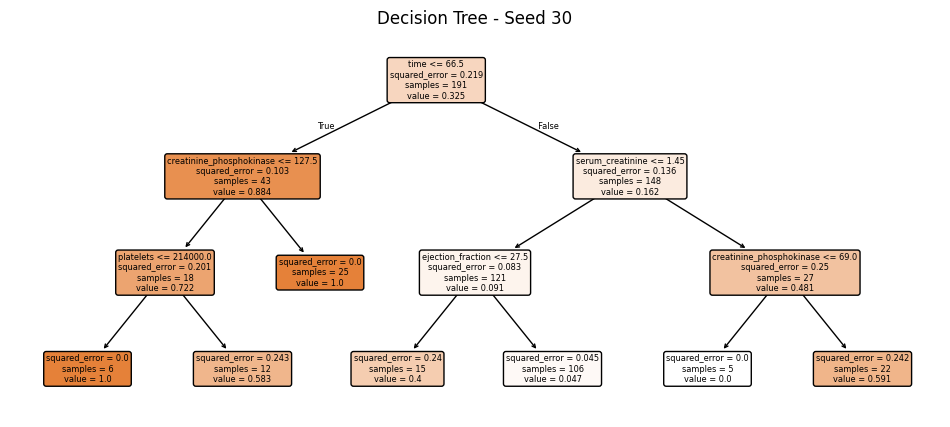

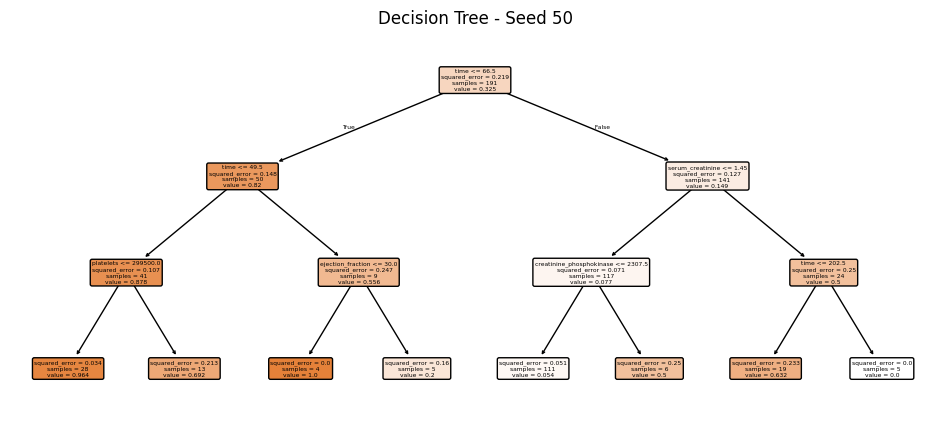

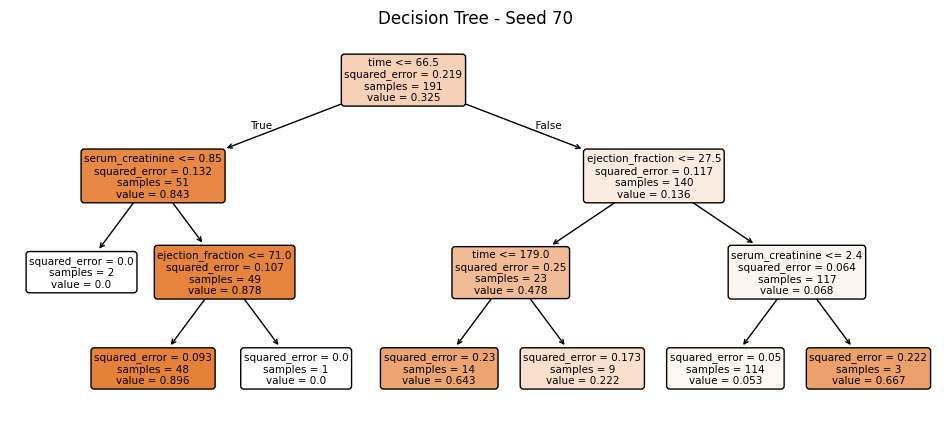

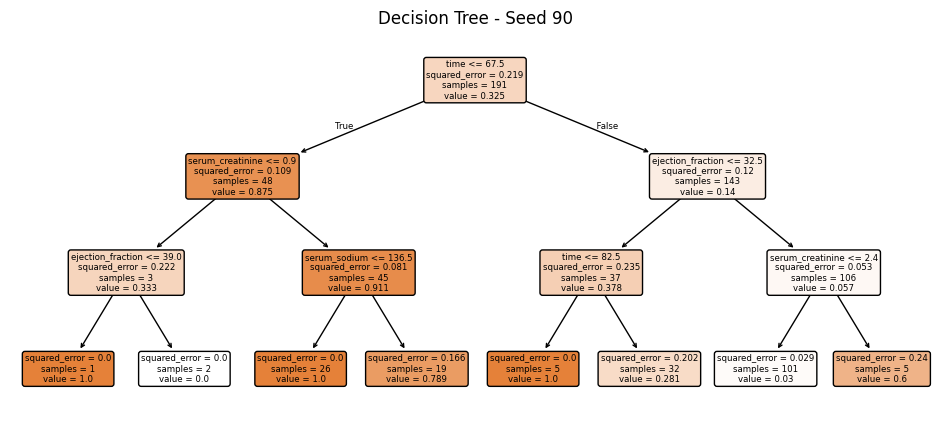

In [7]:
seeds = [30, 50, 70, 90]

tree_predictions = {}
linear_predictions = {}
tree_models = {}
linear_coefficients = {}

for s in seeds:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=0.8,
        random_state=s,
        stratify=y_train
    )

    t = DecisionTreeRegressor(max_depth=3, random_state=s)
    l = LinearRegression()

    t.fit(X_sub, y_sub)
    l.fit(X_sub, y_sub)

    tree_models[s] = t
    tree_predictions[s] = t.predict(X_test)
    linear_predictions[s] = l.predict(X_test)
    linear_coefficients[s] = l.coef_

    print("Seed:", s)
    print("Tree R2:", round(r2_score(y_test, tree_predictions[s]), 4))
    print("Linear R2:", round(r2_score(y_test, linear_predictions[s]), 4))
    print("Tree root feature:", X.columns[t.tree_.feature[0]])
    print()

coef_table = pd.DataFrame(
    linear_coefficients,
    index=X.columns
)

print("Linear coefficients across seeds:")
print(coef_table.round(4))

for s in seeds:
    plt.figure(figsize=(12, 5))
    plot_tree(
        tree_models[s],
        feature_names=X.columns,
        filled=True,
        rounded=True
    )
    plt.title("Decision Tree - Seed " + str(s))
    plt.show()

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [2]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]